3 8
6 2
9 9
8 10
1 16
1 15
0 11
5 8
9 12
3 12
6 10
5 11
9 9
7 5
3 6
2 7
4 12
8 10
7 4
6 9
6 1
2 5
6 4
4 8
1 16
7 3
7 6
2 5
0 14
0 13
9 6
6 4
3 8
0 15
2 6
2 7
3 11
2 6
3 15
3 5
7 12
7 9
1 12
2 6
5 10
3 7
2 4
3 6
8 6
9 9
2 7
8 5
3 9
5 15
7 6
4 10
0 13
0 14
5 17
9 7
8 8
1 12
6 4
4 13
5 11
2 7
7 6
4 13
1 9
0 17
8 9
7 3
8 10
3 8
4 10
9 11
2 7
5 13
1 11
1 10
9 8
1 11
5 11
8 7
8 9
0 11
0 15
0 11
2 6
6 2
5 11
5 14
4 8
1 17
5 7
8 8
1 14
0 16
0 20
3 9
4 8
3 7
8 6
1 10
5 11
7 6
9 7
5 7
9 8
5 9
6 6
4 6
6 5
6 3
0 10
7 4
7 9
7 3
1 9
7 7
0 16
7 4
6 2
8 13
4 10
9 14
3 10
1 8
2 4
8 11
3 11
8 8
5 6
4 15
8 13
3 11
3 9
1 16
0 11
0 11
2 10
0 13
0 21
3 5
0 15
0 14
9 10
4 7
6 7
9 14
3 10
9 11
8 14
8 12
2 3
9 9
8 6
5 11
4 12
2 10
8 7
1 16
9 14
1 12
0 13
2 11
9 11
9 9
5 14
2 10
7 7
6 6
3 12
8 9
7 11
1 11
3 7
9 10
2 11
6 7
6 2
9 7
1 10
5 10
5 10
4 5
7 8
8 15
9 8
6 4
5 16
8 16
0 11
1 13
9 11
2 9
5 11
8 10
3 7
6 6
0 14
7 9
9 12
3 9
7 6
0 15
2 7
3 9
1 13
6 6
8 13
6 6
0 16
7 4
0 15
0 15
1 16
5 14
5 12
4 6
3 6
4 7
4

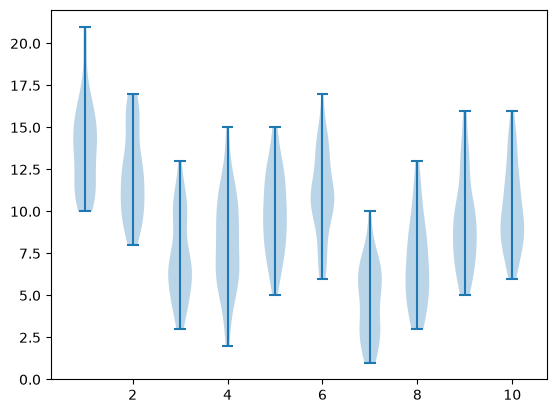

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thu Nov 19 10:48:05 2020

@authors: berar && Oumar
"""

import numpy as np
import matplotlib.pyplot as plt


class Bandit:
    
    def __init__(self, K=10):
        self.K=K
        np.random.seed(5)
        self.variance = np.random.randint(-1,2,size=self.K)
        self.biais = np.random.poisson(3,self.K)
        while sum(self.biais == self.biais.max()) != 1 :
            self.biais = np.random.poisson(3,K)
  
    def get_arm(self,k):   
        reward  = np.random.poisson(6+self.variance[k]) + self.biais[k]  
        return reward


if __name__ == "__main__":
    K=10
    T=500
    bandits = [[]]
    for k in range(K-1):
     bandits.append([]) 

    myBandit = Bandit()

    for t in range(T):
        k = np.random.randint(0,K)
        reward = myBandit.get_arm(k)
        print(k,reward)
        bandits[k].append(reward)
    

    fig = plt.figure()
    plt.violinplot(bandits)
    plt.show()


In [2]:
# Uniform Exploration

[13.8 12.3  6.5  9.2  9.4 10.9  4.4  6.7  8.6  9.2]


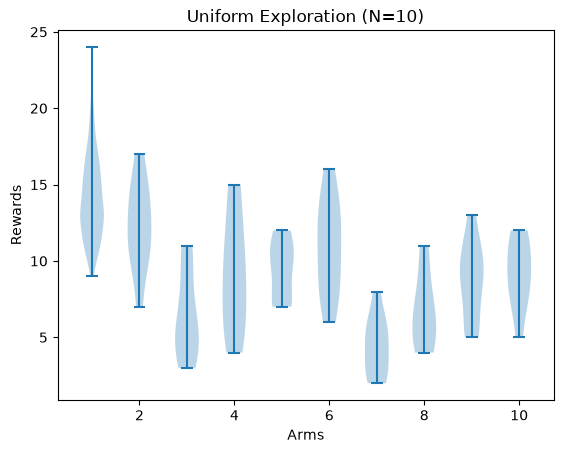

(np.int64(5778), np.int64(0))

In [3]:
K=10
T=500
N = 10

myBandit = Bandit()


def uniform_exploration(myBandit, N, T, plot=False):


    K = myBandit.K

    bandits = []
    for k in range(K):
        bandits.append([]) 

    mean_reward = np.zeros(K)


    # lets explore N time each arm and compute the mean reward for each arm
    for k in range(K):
        for _ in range(N):
            reward = myBandit.get_arm(k)
            bandits[k].append(reward)
        mean_reward[k] = np.mean(bandits[k])


    # select the best arm and pull it for the remaining time
    best_arm = np.argmax(mean_reward)
    print(mean_reward)
    for t in range(N*K, T):
        reward = myBandit.get_arm(best_arm)
        bandits[best_arm].append(reward)
    
    cumulative_reward = np.sum(bandits[best_arm])

    if plot:
        plt.figure()
        plt.violinplot(bandits)
        plt.title(f"Uniform Exploration (N={N})")
        plt.xlabel("Arms")
        plt.ylabel("Rewards")
        plt.show()


    return cumulative_reward, best_arm


uniform_exploration(myBandit, N, T, plot=True)

# Estimation empirique du regret — Uniform Exploration

**Définition.** Le regret après $T$ tours compare ce qu'on a gagné à ce qu'aurait gagné un joueur qui tire toujours le meilleur bras :

$$R(T) = T\,\mu^* - \mathbb{E}\Big[\sum_{t=1}^{T} r_t\Big], \qquad \mu^* = \max_k \mu_k$$

On ne peut pas calculer l'espérance analytiquement (le choix du bras après exploration est aléatoire), donc on l'estime par **Monte-Carlo** :

1. **Estimer les vraies moyennes $\mu_k$** en tirant chaque bras un très grand nombre de fois (méthode "oracle" : on a accès au simulateur, donc on peut se le permettre hors de l'algorithme).
2. **Rejouer l'algorithme $M$ fois indépendamment** et enregistrer à chaque pas le bras choisi $a_t$ et la récompense $r_t$.
3. Calculer pour chaque run
   - le **regret réalisé** : $T\mu^* - \sum_t r_t$ (bruité par le hasard des récompenses),
   - le **pseudo-regret** : $\sum_t (\mu^* - \mu_{a_t}) = \sum_k n_k(T)\,\Delta_k$ avec $\Delta_k = \mu^*-\mu_k$ (même espérance, beaucoup moins de variance).
4. **Moyenner sur les $M$ runs** → $\hat R(T)$, avec un intervalle de confiance à 95 % : $\hat R \pm 1.96\,\hat\sigma/\sqrt{M}$.

Remarques importantes sur le code existant :
- `Bandit.__init__` fait `np.random.seed(5)` : il faut **créer le bandit une seule fois**, sinon tous les runs Monte-Carlo sont identiques.
- `uniform_exploration` renvoie `np.sum(bandits[best_arm])`, qui oublie les récompenses d'exploration des autres bras. Pour le regret, il faut **toutes** les récompenses, d'où la version "trace" ci-dessous.

In [4]:
# 1) Estimation empirique des vraies moyennes mu_k (oracle Monte-Carlo)
def estimate_true_means(myBandit, n_samples=100_000):
    return np.array([np.mean([myBandit.get_arm(k) for _ in range(n_samples)])
                     for k in range(myBandit.K)])

myBandit = Bandit()          # créé UNE seule fois (seed fixé dans __init__)
mu_hat = estimate_true_means(myBandit)
mu_theo = 6 + myBandit.variance + myBandit.biais   # E[Poisson(6+v)] + biais, pour vérifier

mu_star = mu_hat.max()
best_true_arm = np.argmax(mu_hat)
gaps = mu_star - mu_hat

print("mu estimées :", np.round(mu_hat, 2))
print("mu théoriques:", mu_theo)
print("meilleur bras:", best_true_arm, " mu* =", round(mu_star, 2))
print("gaps Delta_k :", np.round(gaps, 2))

mu estimées : [14.01 12.    6.99  8.   10.01 11.    5.    7.01  9.   10.  ]
mu théoriques: [14 12  7  8 10 11  5  7  9 10]
meilleur bras: 0  mu* = 14.01
gaps Delta_k : [0.   2.01 7.02 6.02 4.01 3.02 9.01 7.01 5.01 4.01]


In [5]:
# 2) Version de uniform_exploration qui garde la trace complète (bras + récompense à chaque t)
def uniform_exploration_trace(myBandit, N, T):
    K = myBandit.K
    arms = np.empty(T, dtype=int)
    rewards = np.empty(T)
    mean_reward = np.zeros(K)

    t = 0
    for k in range(K):                      # phase d'exploration : N tirages par bras
        for _ in range(N):
            arms[t] = k
            rewards[t] = myBandit.get_arm(k)
            t += 1
        mean_reward[k] = rewards[t-N:t].mean()

    best_arm = np.argmax(mean_reward)
    for s in range(t, T):                   # phase d'exploitation
        arms[s] = best_arm
        rewards[s] = myBandit.get_arm(best_arm)

    return arms, rewards, best_arm

In [6]:
# 3) Estimation Monte-Carlo du regret
def empirical_regret_uniform(myBandit, N, T, mu, M=1000):
    mu_star = mu.max()
    pseudo_curves = np.zeros((M, T))   # pseudo-regret cumulé R(t) pour chaque run
    realized = np.zeros(M)             # regret réalisé final pour chaque run
    good_choice = np.zeros(M, dtype=bool)

    for m in range(M):
        arms, rewards, best_arm = uniform_exploration_trace(myBandit, N, T)
        pseudo_curves[m] = np.cumsum(mu_star - mu[arms])
        realized[m] = T * mu_star - rewards.sum()
        good_choice[m] = (best_arm == np.argmax(mu))

    return pseudo_curves, realized, good_choice


def summarize(values, M):
    m, s = values.mean(), values.std(ddof=1)
    return m, 1.96 * s / np.sqrt(M)


T, N, M = 500, 10, 1000
pseudo_curves, realized, good_choice = empirical_regret_uniform(myBandit, N, T, mu_hat, M)

m_p, ci_p = summarize(pseudo_curves[:, -1], M)
m_r, ci_r = summarize(realized, M)
print(f"Pseudo-regret  R(T={T}) ≈ {m_p:.1f} ± {ci_p:.1f}")
print(f"Regret réalisé R(T={T}) ≈ {m_r:.1f} ± {ci_r:.1f}")
print(f"P(bon bras choisi après exploration) ≈ {good_choice.mean():.3f}")

# Décomposition : coût d'exploration (déterministe) + coût d'exploitation (aléatoire)
explo = N * gaps.sum()
print(f"  dont exploration  : N * sum(Delta_k) = {explo:.1f}")
print(f"  dont exploitation : {m_p - explo:.1f}")

Pseudo-regret  R(T=500) ≈ 501.4 ± 10.0
Regret réalisé R(T=500) ≈ 508.5 ± 10.5
P(bon bras choisi après exploration) ≈ 0.965
  dont exploration  : N * sum(Delta_k) = 471.2
  dont exploitation : 30.2


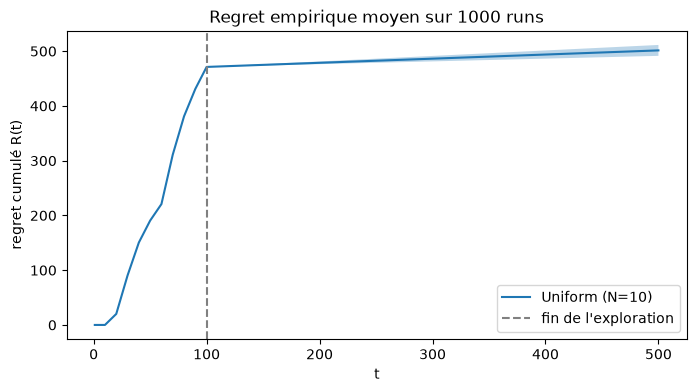

In [7]:
# 4) Courbe de regret moyen R(t) avec bande de confiance
mean_curve = pseudo_curves.mean(axis=0)
ci_curve = 1.96 * pseudo_curves.std(axis=0, ddof=1) / np.sqrt(M)
ts = np.arange(1, T + 1)

plt.figure(figsize=(8, 4))
plt.plot(ts, mean_curve, label=f"Uniform (N={N})")
plt.fill_between(ts, mean_curve - ci_curve, mean_curve + ci_curve, alpha=0.3)
plt.axvline(N * myBandit.K, ls="--", c="gray", label="fin de l'exploration")
plt.xlabel("t"); plt.ylabel("regret cumulé R(t)")
plt.title(f"Regret empirique moyen sur {M} runs")
plt.legend(); plt.show()

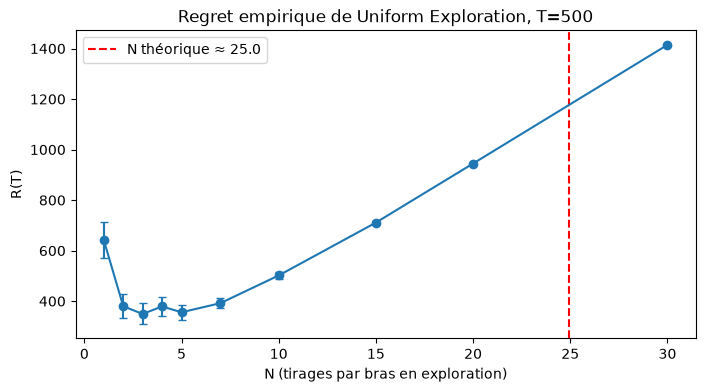

N optimal empirique : 3


In [8]:
# 5) Influence de N : regret final en fonction du budget d'exploration
Ns = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30]
means, cis = [], []
for n in Ns:
    curves, _, _ = empirical_regret_uniform(myBandit, n, T, mu_hat, M=500)
    m, ci = summarize(curves[:, -1], 500)
    means.append(m); cis.append(ci)

K = myBandit.K
N_theo = (T / K) ** (2/3) * np.log(T) ** (1/3)   # choix théorique N ~ (T/K)^(2/3) (log T)^(1/3)

plt.figure(figsize=(8, 4))
plt.errorbar(Ns, means, yerr=cis, marker="o", capsize=3)
plt.axvline(N_theo, ls="--", c="red", label=f"N théorique ≈ {N_theo:.1f}")
plt.xlabel("N (tirages par bras en exploration)"); plt.ylabel("R(T)")
plt.title(f"Regret empirique de Uniform Exploration, T={T}")
plt.legend(); plt.show()

print("N optimal empirique :", Ns[int(np.argmin(means))])

#  epsilon greedy

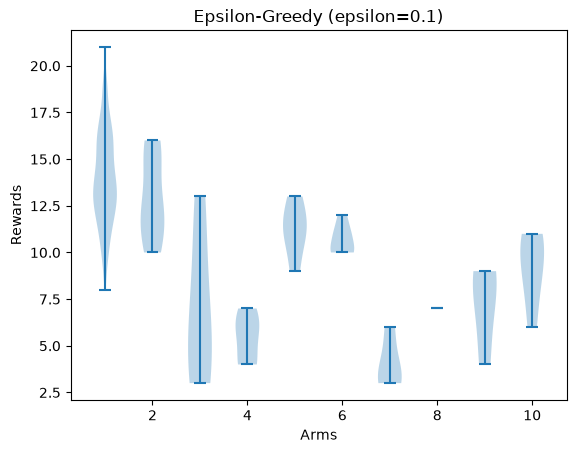

(np.int64(6304), np.int64(0))

In [9]:


def epsilon_greedy(myBandit, N, T, epsilon=0.1, plot=False):
    K = myBandit.K
   
    bandits = [[]]
    for k in range(K):
        bandits.append([]) 

    mean_reward = np.zeros(K)



    Q_a = np.zeros(K)  
    n_a = np.zeros(K)  

    for t in range(T):
        if np.random.rand() < epsilon:
            
            k = np.random.randint(0, K)
        else:
            k = np.argmax(Q_a)

        reward = myBandit.get_arm(k)
        bandits[k].append(reward)

        n_a[k] += 1
        Q_a[k] += (reward - Q_a[k]) / n_a[k]

    best_arm = np.argmax(Q_a)
    cumulative_reward = np.sum(bandits[best_arm])

    if plot:
        plt.figure()
        plt.violinplot(bandits)
        plt.title(f"Epsilon-Greedy (epsilon={epsilon})")
        plt.xlabel("Arms")
        plt.ylabel("Rewards")
        plt.show()

    return cumulative_reward, best_arm



epsilon_greedy(myBandit, N, T, epsilon=0.1, plot=True)

# Successive elimation

/home/ba/miniconda3/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ba/miniconda3/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


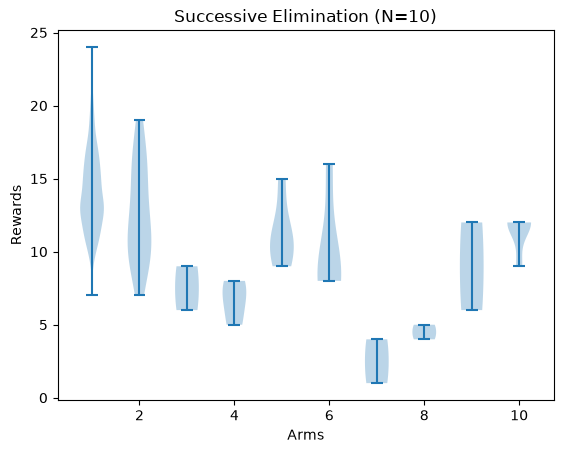

[500, 18, 2, 3, 5, 5, 2, 2, 2, 5]


(np.int64(7065), np.int64(0))

In [10]:
K=10
T=500
N = 10

myBandit = Bandit()


def succesive_elimination(myBandit, plot=False):
    K = myBandit.K
    bandits = []
    for k in range(K):
        bandits.append([]) 
    
    n_t = np.zeros(K) + 1
    rt = np.zeros(K) + 1
    rt = 2*np.log10(T)/n_t
    ubc = np.zeros(K) + 2*np.log10(T)/n_t 
    lcb = np.zeros(K) - 2*np.log10(T)/n_t 
    active_arms= np.ones(K)

    for t in range(T):
        # recupération des indices des bras actifs
        active_arms_idx= [idx[0] for idx in np.argwhere(active_arms)]
        for idx in active_arms_idx:
            # calcul des bornes supérieures et inférieures de confiance
            rt[idx] = 2*np.log10(T)/n_t[idx]
            ubc[idx] = np.mean(bandits[idx]) + rt[idx]
            lcb[idx] = np.mean(bandits[idx]) - rt[idx]
            # desactivation des bras inutiles
            if np.any(ubc[idx] < lcb):
                active_arms[idx] = 0

        # on tire un échantillon de chaque bras actif
        for k in active_arms_idx:
            reward = myBandit.get_arm(k)
            bandits[k].append(reward)
            n_t[k] += 1




    if plot:
            plt.figure()
            plt.violinplot(bandits)
            plt.title(f"Successive Elimination (N={N})")
            plt.xlabel("Arms")
            plt.ylabel("Rewards")
            plt.show()

    print([len(bandits[k]) for k in range(K)])
    best_arm = np.argmax([np.sum(bandits[k]) for k in range(K)])

    cumulative_reward = np.sum(bandits[best_arm])

    return cumulative_reward, best_arm  




        

            
        
succesive_elimination(myBandit, plot=True)



    

# UCB1

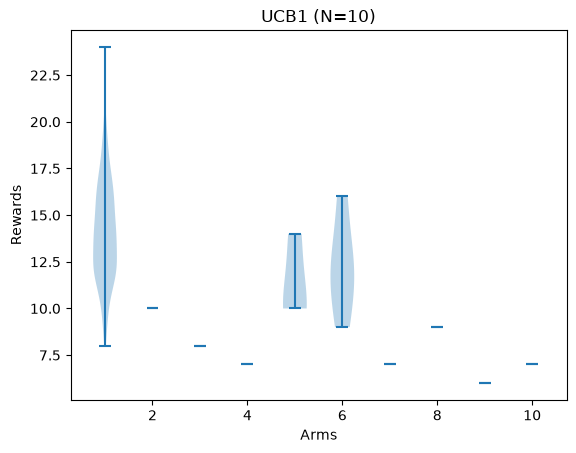

(np.int64(6818), np.int64(0))

In [11]:

def ucb1(myBandit, plot=False):
    K = myBandit.K
    bandits = []

    for k in range(K):
        bandits.append([]) 

    ucbs = np.zeros(K)
    for k in range(K):
        
        reward = myBandit.get_arm(k)
        bandits[k].append(reward)

    for t in range(K, T):
        for k in range(K):
            ucbs[k] = np.mean(bandits[k]) + np.sqrt(2*np.log(T)/len(bandits[k]))

        k = np.argmax(ucbs)
        reward = myBandit.get_arm(k)
        bandits[k].append(reward)


    if plot:
            plt.figure()
            plt.violinplot(bandits)
            plt.title(f"UCB1 (N={N})")
            plt.xlabel("Arms")
            plt.ylabel("Rewards")
            plt.show()


    best_arm = np.argmax([np.sum(bandits[k]) for k in range(K)])
    cumulative_reward = np.sum(bandits[best_arm])
    return cumulative_reward, best_arm


        
ucb1(myBandit, plot=True)


